In [6]:
# Load the clean splits and define the target columns

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
np.random.seed(42)

train_df = pd.read_csv("../data/processed/marketing_train.csv")
test_df = pd.read_csv("../data/processed/marketing_test.csv")

cat_cols = ["Education", "Marital_Status"]
spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
channel_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]
num_cols = ["Age", "Income", "Kidhome", "Teenhome", "Recency"] + spend_cols + channel_cols + ["Response"]
cols = cat_cols + num_cols

# Structural zero ceilings when Income < $30,000 (established in Notebook 1 Cell 6)
sz_ceilings = {
    "MntWines": 300, "MntMeatProducts": 300, "MntGoldProds": 270,
    "MntFishProducts": 150, "MntSweetProducts": 160, "MntFruits": 100
}

real_train = train_df[cols].copy()
real_test = test_df[cols].copy()
N = len(real_train)

print(f"Real Train Shape: {real_train.shape} | Real Test Shape: {real_test.shape}")

Real Train Shape: (1764, 19) | Real Test Shape: (441, 19)


In [8]:
# Method 0 and Method 1: Naive Indepedent Baseline and Stratified Contingency /IPF-Style

# --- Method 0: Naive Independent Sampling ---
syn_naive = pd.DataFrame()
for c in cols:
    syn_naive[c] = np.random.choice(real_train[c], size=N, replace=True)

# --- Method 1: Stratified Contingency Sampling /IPF-Style ---
temp = real_train.copy()
temp["Inc_Bin"] = pd.qcut(temp["Income"], q=4, labels=False)
strata = ["Education", "Marital_Status", "Kidhome", "Inc_Bin"]

sampled_strata = temp[strata].sample(n=N, replace=True, random_state=42)
grouped = {k: g for k, g in temp.groupby(strata)}

rows = []
for _, s_row in sampled_strata.iterrows():
    group_df = grouped[tuple(s_row)]
    rows.append({c: np.random.choice(group_df[c]) for c in cols})

syn_ipf = pd.DataFrame(rows)[cols]

syn_naive.to_csv("../data/synthetic_stage1/synth_naive.csv", index=False)
syn_ipf.to_csv("../data/synthetic_stage1/synth_ipf.csv", index=False)
print("Generated Method 0 (Naive) and Method 1 (Stratified Contingency).")

Generated Method 0 (Naive) and Method 1 (Stratified Contingency).


In [ ]:
# Method 2:  Gausian Copula (Sklar's Theorem)

from sklearn.preprocessing import QuantileTransformer

work = real_train.copy()

# Order categorical variables by mean income for smooth rank mapping
cat_orders = {}
for c in cat_cols:
    order = work.groupby(c)["Income"].mean().sort_values().index.tolist()
    cat_orders[c] = order
    work[c] = work[c].map({val: i for i, val in enumerate(order)})

# Transform marginals to standard normal space Z
X_jitter = work.values.astype(float) + np.random.normal(0, 1e-4, work.shape)
qt = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=42)
Z = qt.fit_transform(X_jitter)

# Sample from multivariate normal with learned covariance
cov_Z = np.cov(Z, rowvar=False) + np.eye(Z.shape[1]) * 1e-6
Z_syn = np.random.multivariate_normal(np.zeros(Z.shape[1]), cov_Z, size=N)

# Inverse transform back to original feature scales
syn_copula = pd.DataFrame(qt.inverse_transform(Z_syn), columns=cols)

for c in cat_cols:
    order = cat_orders[c]
    idx = np.clip(np.round(syn_copula[c]).astype(int), 0, len(order) - 1)
    syn_copula[c] = [order[i] for i in idx]

for c in num_cols:
    syn_copula[c] = np.clip(np.round(syn_copula[c]), real_train[c].min(), real_train[c].max()).astype(int)

syn_copula.to_csv("../data/synthetic_stage1/synth_copula.csv", index=False)
print("Generated Method 2 (Gaussian Copula).")

Generated Method 2 (Gaussian Copula).


In [11]:
from pgmpy.estimators import HillClimbSearch, BIC
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.sampling import BayesianModelSampling

disc_df = pd.DataFrame()
binned_cols = []

for c in cols:
    if c in cat_cols or real_train[c].nunique() <= 6:
        disc_df[c] = real_train[c].astype(str)
    else:
        disc_df[c] = pd.qcut(real_train[c], q=5, labels=False, duplicates="drop").astype(str)
        binned_cols.append(c)

# Learn DAG structure and fit conditional probability tables
dag = HillClimbSearch(disc_df).estimate(scoring_method=BIC(disc_df), max_indegree=3, show_progress=False)
bn = DiscreteBayesianNetwork(dag.edges())
bn.add_nodes_from(cols)
bn.fit(disc_df)

# Forward sample discrete bins and map back to empirical values within each bin
syn_disc = BayesianModelSampling(bn).forward_sample(size=N, seed=42, show_progress=False)
syn_bn = pd.DataFrame()

for c in cols:
    if c in cat_cols:
        syn_bn[c] = syn_disc[c]
    elif c not in binned_cols:
        syn_bn[c] = syn_disc[c].astype(float).astype(int)
    else:
        bin_map = {b: real_train[c].values[disc_df[c].values == b] for b in disc_df[c].unique()}
        syn_bn[c] = [np.random.choice(bin_map[b]) for b in syn_disc[c]]

syn_bn.to_csv("../data/synthetic_stage1/synth_bn.csv", index=False)
print(f"Generated Method 3 (Bayesian Network) with {len(dag.edges())} learned DAG edges.")

C:\Users\User\AppData\Local\Temp\ipykernel_5320\1944319916.py:16: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  dag = HillClimbSearch(disc_df).estimate(scoring_method=BIC(disc_df), max_indegree=3, show_progress=False)


Generated Method 3 (Bayesian Network) with 20 learned DAG edges.


In [14]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer

torch.manual_seed(42)

qt_tvae = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=42)
X_num = qt_tvae.fit_transform(real_train[num_cols].values.astype(float))

ohe = OneHotEncoder(sparse_output=False)
X_cat = ohe.fit_transform(real_train[cat_cols])

X_all = np.hstack([X_num, X_cat]).astype(np.float32)
in_dim, n_num, latent_dim = X_all.shape[1], len(num_cols), 16

class TVAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(in_dim, 128), nn.SiLU(), nn.Linear(128, 64), nn.SiLU())
        self.mu = nn.Linear(64, latent_dim)
        self.logvar = nn.Linear(64, latent_dim)
        self.dec = nn.Sequential(nn.Linear(latent_dim, 64), nn.SiLU(), nn.Linear(64, 128), nn.SiLU(), nn.Linear(128, in_dim))

    def forward(self, x):
        h = self.enc(x)
        mu, logvar = self.mu(h), self.logvar(h)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.dec(z), mu, logvar

tvae = TVAE()
opt = torch.optim.AdamW(tvae.parameters(), lr=3e-3)
loader = DataLoader(TensorDataset(torch.from_numpy(X_all)), batch_size=128, shuffle=True)

for epoch in range(250):
    for (bx,) in loader:
        opt.zero_grad()
        recon, mu, logvar = tvae(bx)
        loss_num = nn.functional.mse_loss(recon[:, :n_num], bx[:, :n_num], reduction="sum")
        loss_cat = nn.functional.binary_cross_entropy_with_logits(recon[:, n_num:], bx[:, n_num:], reduction="sum")
        kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        ((loss_num + loss_cat + 0.2 * kld) / len(bx)).backward()
        opt.step()

with torch.no_grad():
    out = tvae.dec(torch.randn(N, latent_dim)).numpy()

syn_tvae = pd.DataFrame(qt_tvae.inverse_transform(out[:, :n_num]), columns=num_cols)
for c in num_cols:
    syn_tvae[c] = np.clip(np.round(syn_tvae[c]), real_train[c].min(), real_train[c].max()).astype(int)

idx = n_num
for c, cats in zip(cat_cols, ohe.categories_):
    logits = out[:, idx:idx + len(cats)]
    probs = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs /= probs.sum(axis=1, keepdims=True)
    syn_tvae[c] = [np.random.choice(cats, p=p) for p in probs]
    idx += len(cats)

syn_tvae = syn_tvae[cols]
syn_tvae.to_csv("../data/synthetic_stage1/synth_tvae.csv", index=False)
print("Generated Method 4 (Deep TVAE).")

Generated Method 4 (Deep TVAE).


In [15]:
# Stage 1 Benchmark Scorecard

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

models = {
    "0. Naive Independent": syn_naive,
    "1. Stratified Contingency": syn_ipf,
    "2. Gaussian Copula": syn_copula,
    "3. Bayesian Network": syn_bn,
    "4. Deep TVAE": syn_tvae
}

def tstr_auc(train_data):
    feat_num = [c for c in num_cols if c != "Response"]
    prep = ColumnTransformer([
        ("num", StandardScaler(), feat_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])
    X_tr = prep.fit_transform(train_data)
    X_te = prep.transform(real_test)
    clf = LogisticRegression(max_iter=1000).fit(X_tr, train_data["Response"])
    return roc_auc_score(real_test["Response"], clf.predict_proba(X_te)[:, 1])

R_real = real_train[num_cols].corr(method="spearman").values
real_ceiling_auc = tstr_auc(real_train)

results = []
for name, syn_df in models.items():
    # 1. 1D KS Similarity
    ks_sim = np.mean([1 - stats.ks_2samp(real_train[c], syn_df[c]).statistic for c in num_cols])
    
    # 2. 2D Correlation Frobenius Error
    R_syn = syn_df[num_cols].corr(method="spearman").fillna(0).values
    corr_err = np.linalg.norm(R_real - R_syn, ord="fro")
    
    # 3. 6-Category Structural Zero Violations % (Income < $30k & Spend > ceiling)
    low_inc = syn_df["Income"] < 30000
    sz_viol = pd.Series(False, index=syn_df.index)
    for col, ceiling in sz_ceilings.items():
        sz_viol = sz_viol | (low_inc & (syn_df[col] > ceiling))
    
    # 4. Cross-Feature Consistency Violations % (Spend > 40% Income OR Spend > 0 with 0 channel purchases)
    tot_spend = syn_df[spend_cols].sum(axis=1)
    act_purch = syn_df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
    cf_viol = (tot_spend > 0.40 * syn_df["Income"]) | ((tot_spend > 0) & (act_purch == 0))
    
    # 5. Downstream TSTR ROC-AUC
    auc = tstr_auc(syn_df)
    
    results.append({
        "Generator Model": name,
        "1D KS Similarity (↑)": round(ks_sim, 3),
        "2D Corr Error (↓)": round(corr_err, 2),
        "6-Cat Struct Zero % (↓)": round(sz_viol.mean() * 100, 2),
        "Cross-Feature Viol % (↓)": round(cf_viol.mean() * 100, 2),
        "TSTR ROC-AUC (↑)": round(auc, 3),
        "AUC Retention %": round((auc / real_ceiling_auc) * 100, 1)
    })

scorecard = pd.DataFrame(results)
scorecard.to_csv("../outputs/tables/stage1_benchmark_scorecard.csv", index=False)
print(f"=== STAGE 1 BENCHMARK SCORECARD (Real Data Ceiling ROC-AUC = {real_ceiling_auc:.3f}) ===")
display(scorecard)

=== STAGE 1 BENCHMARK SCORECARD (Real Data Ceiling ROC-AUC = 0.874) ===


,Generator Model,1D KS Similarity (↑),2D Corr Error (↓),6-Cat Struct Zero % (↓),Cross-Feature Viol % (↓),TSTR ROC-AUC (↑),AUC Retention %
0,0. Naive Independent,0.985,7.18,9.75,0.06,0.434,49.6
1,1. Stratified Contingency,0.986,1.72,0.34,0.00,0.714,81.6
2,2. Gaussian Copula,0.980,1.86,0.57,0.11,0.811,92.7
3,3. Bayesian Network,0.984,2.12,0.28,0.00,0.746,85.3
4,4. Deep TVAE,0.924,1.83,0.00,0.00,0.793,90.6


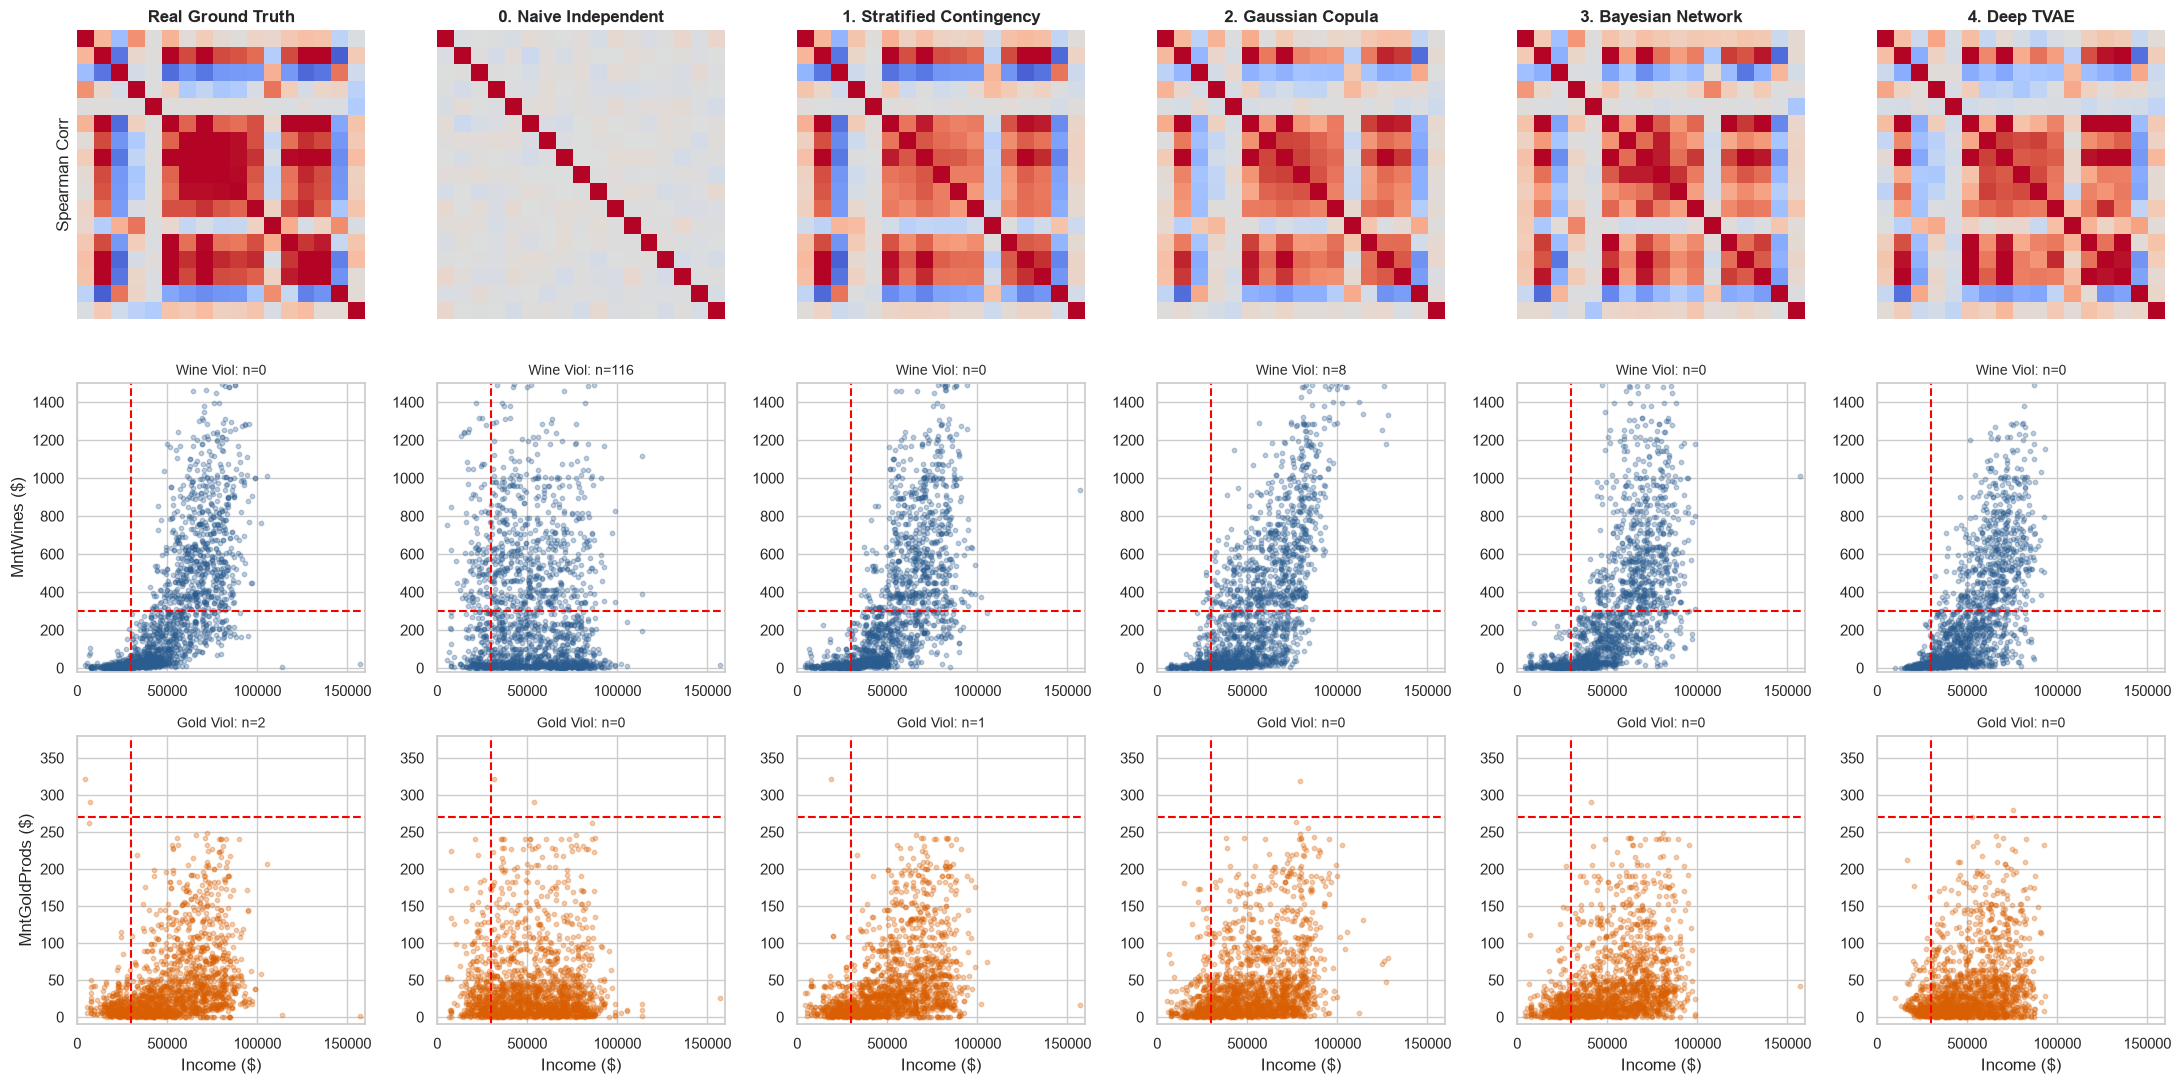

In [16]:
# Visual Comparison: Correlation Recovery & Multi-Category Structural Zeros

fig, axes = plt.subplots(3, 6, figsize=(22, 11))

all_sets = [("Real Ground Truth", real_train)] + list(models.items())

for i, (name, data) in enumerate(all_sets):
    # Row 0: Correlation Heatmap
    sns.heatmap(
        data[num_cols].corr(method="spearman"),
        ax=axes[0, i], cmap="coolwarm", vmin=-0.7, vmax=0.7,
        cbar=False, xticklabels=False, yticklabels=False
    )
    axes[0, i].set_title(name, fontweight="bold")
    
    # Row 1: Income vs MntWines
    axes[1, i].scatter(data["Income"], data["MntWines"], alpha=0.3, s=10, color="#2b5c8f")
    axes[1, i].axvline(30000, color="red", linestyle="--")
    axes[1, i].axhline(300, color="red", linestyle="--")
    axes[1, i].set_xlim(0, 160000)
    axes[1, i].set_ylim(-20, 1500)
    viol_w = ((data["Income"] < 30000) & (data["MntWines"] > 300)).sum()
    axes[1, i].set_title(f"Wine Viol: n={viol_w}", fontsize=10)
    
    # Row 2: Income vs MntGoldProds
    axes[2, i].scatter(data["Income"], data["MntGoldProds"], alpha=0.3, s=10, color="#d95f02")
    axes[2, i].axvline(30000, color="red", linestyle="--")
    axes[2, i].axhline(270, color="red", linestyle="--")
    axes[2, i].set_xlim(0, 160000)
    axes[2, i].set_ylim(-10, 380)
    axes[2, i].set_xlabel("Income ($)")
    viol_g = ((data["Income"] < 30000) & (data["MntGoldProds"] > 270)).sum()
    axes[2, i].set_title(f"Gold Viol: n={viol_g}", fontsize=10)

axes[0, 0].set_ylabel("Spearman Corr")
axes[1, 0].set_ylabel("MntWines ($)")
axes[2, 0].set_ylabel("MntGoldProds ($)")

plt.tight_layout()
plt.savefig("../outputs/figures/06_stage1_full_benchmark.png")
plt.show()